# Ứng dụng Machine Learning trên Kho dữ liệu Tuyển dụng CNTT (`IT_Job_Market_DW`)

**Đề tài:** *Xây dựng kho dữ liệu tuyển dụng ngành công nghệ thông tin nhằm hỗ trợ sinh viên lựa chọn kỹ năng và định hướng nghề nghiệp tại Việt Nam.*

---

### Cấu trúc Notebook
1. **Phần 1 — Kết nối & Truy vấn Kho dữ liệu (`SQL Server DW`)**: Đọc các bảng Fact và Dimension từ `IT_Job_Market_DW`.
2. **Phần 2 — Phân tích Khám phá Nhu cầu Thị trường (EDA)**: Thống kê phân bố nhóm ngành, cấp bậc và top kỹ năng.
3. **Phần 3 — Bài toán 1 (Dự đoán Kỹ năng cần thiết cho Sinh viên CNTT)**: Mô hình phân loại đa nhãn (*Multi-Label Classification*) dự báo xác suất kỹ năng cần thiết theo vị trí và cấp bậc.
4. **Phần 4 — Bài toán 2 (Định hướng Nhóm Nghề nghiệp từ Hồ sơ Kỹ năng)**: Mô hình phân loại đa lớp (*Multi-Class Classification*) & phân tích độ quan trọng của kỹ năng (*Feature Importance*).
5. **Phần 5 — Hệ thống Gợi ý Lộ trình Học tập (Skill Gap) & Định hướng Nghề nghiệp**: Tư vấn trực tiếp cho từng hồ sơ sinh viên.

## Phần 1: Thiết lập Môi trường & Tải dữ liệu từ SQL Server DW
### 1.1. Import thư viện

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import pyodbc
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, hamming_loss, roc_auc_score
)

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

### 1.2. Kết nối SQL Server Data Warehouse (`IT_Job_Market_DW`) và đọc bảng Fact / Dimension

In [2]:
CONN_STR = os.environ.get(
    "DW_SQLSERVER_CONNECTION_STRING",
    "DRIVER={ODBC Driver 18 for SQL Server};SERVER=DESKTOP-BNVB0UT;"
    "DATABASE=IT_Job_Market_DW;Trusted_Connection=yes;Encrypt=yes;TrustServerCertificate=yes"
)

with pyodbc.connect(CONN_STR) as conn:
    jobs = pd.read_sql("""
        SELECT f.fact_job_key, f.job_id, f.source, f.title, f.company_name,
               f.observed_date_key, d.calendar_date
        FROM dw.fact_job f
        JOIN dw.dim_date d ON d.date_key = f.observed_date_key
    """, conn)

    skills = pd.read_sql("""
        SELECT f.fact_job_key, d.necessary_skill_key, d.skill_type,
               d.name AS skill_name, d.category, f.level_text, f.skill_mention_count
        FROM dw.fact_job_necessary_skill f
        JOIN dw.dim_necessary_skill d ON d.necessary_skill_key = f.necessary_skill_key
    """, conn)

    roles = pd.read_sql("SELECT fact_job_key, role_key, name AS role_name, category AS role_category FROM dw.dim_role", conn)
    levels = pd.read_sql("SELECT fact_job_key, level_key, name AS level_name FROM dw.dim_level", conn)
    cities = pd.read_sql("SELECT fact_job_key, city_key, name AS city_name FROM dw.dim_city", conn)

### 1.3. Tổng quan quy mô dữ liệu trong Kho dữ liệu

In [3]:
summary_df = pd.DataFrame([
    {"Bảng trong SQL Server DW": "dw.fact_job", "Ý nghĩa": "Tin tuyển dụng CNTT hợp lệ mới nhất", "Số bản ghi": len(jobs), "Số thực thể duy nhất": jobs["job_id"].nunique()},
    {"Bảng trong SQL Server DW": "dw.fact_job_necessary_skill", "Ý nghĩa": "Liên kết Tin tuyển dụng - Kỹ năng & Ngoại ngữ", "Số bản ghi": len(skills), "Số thực thể duy nhất": skills["necessary_skill_key"].nunique()},
    {"Bảng trong SQL Server DW": "dw.dim_role", "Ý nghĩa": "Vị trí công việc & Nhóm ngành CNTT", "Số bản ghi": len(roles), "Số thực thể duy nhất": roles["role_name"].nunique()},
    {"Bảng trong SQL Server DW": "dw.dim_level", "Ý nghĩa": "Cấp bậc kinh nghiệm (Intern -> Senior/Lead)", "Số bản ghi": len(levels), "Số thực thể duy nhất": levels["level_name"].nunique()},
    {"Bảng trong SQL Server DW": "dw.dim_city", "Ý nghĩa": "Tỉnh / Thành phố làm việc", "Số bản ghi": len(cities), "Số thực thể duy nhất": cities["city_name"].nunique()},
])
summary_df

Bảng trong SQL Server DW,Ý nghĩa,Số bản ghi,Số thực thể duy nhất
dw.fact_job,Tin tuyển dụng CNTT hợp lệ mới nhất,580,580
dw.fact_job_necessary_skill,Liên kết Tin tuyển dụng - Kỹ năng & Ngoại ngữ,3023,319
dw.dim_role,Vị trí công việc & Nhóm ngành CNTT,676,59
dw.dim_level,Cấp bậc kinh nghiệm (Intern -> Senior/Lead),598,10
dw.dim_city,Tỉnh / Thành phố làm việc,627,6


## Phần 2: Phân tích Khám phá Nhu cầu Thị trường (EDA)
### 2.1. Top 15 kỹ năng được nhà tuyển dụng yêu cầu nhiều nhất

In [4]:
top_skills_df = (
    skills.groupby(["skill_type", "skill_name"])["fact_job_key"]
    .nunique()
    .reset_index(name="Số tin yêu cầu")
    .sort_values("Số tin yêu cầu", ascending=False)
    .head(15)
    .reset_index(drop=True)
)
top_skills_df.insert(0, "Hạng", range(1, len(top_skills_df) + 1))
top_skills_df["Tỷ lệ tin (%)"] = (top_skills_df["Số tin yêu cầu"] * 100.0 / len(jobs)).round(1)
top_skills_df = top_skills_df.rename(columns={"skill_type": "Nhóm kỹ năng", "skill_name": "Tên kỹ năng"})
top_skills_df

Hạng,Nhóm kỹ năng,Tên kỹ năng,Số tin yêu cầu,Tỷ lệ tin (%)
1,foreign_language,English,348,60.0
2,programming_language,Python,128,22.1
3,core_skill,SQL,102,17.6
4,core_skill,AI,96,16.6
5,programming_language,Java,85,14.7
6,core_skill,AWS,58,10.0
7,core_skill,API,50,8.6
8,core_skill,DevOps,49,8.4
9,core_skill,Agile,45,7.8
10,core_skill,CI/CD,44,7.6


### 2.2. Biểu đồ phân bố nhu cầu theo Nhóm ngành (`dw.dim_role`) và Cấp bậc (`dw.dim_level`)

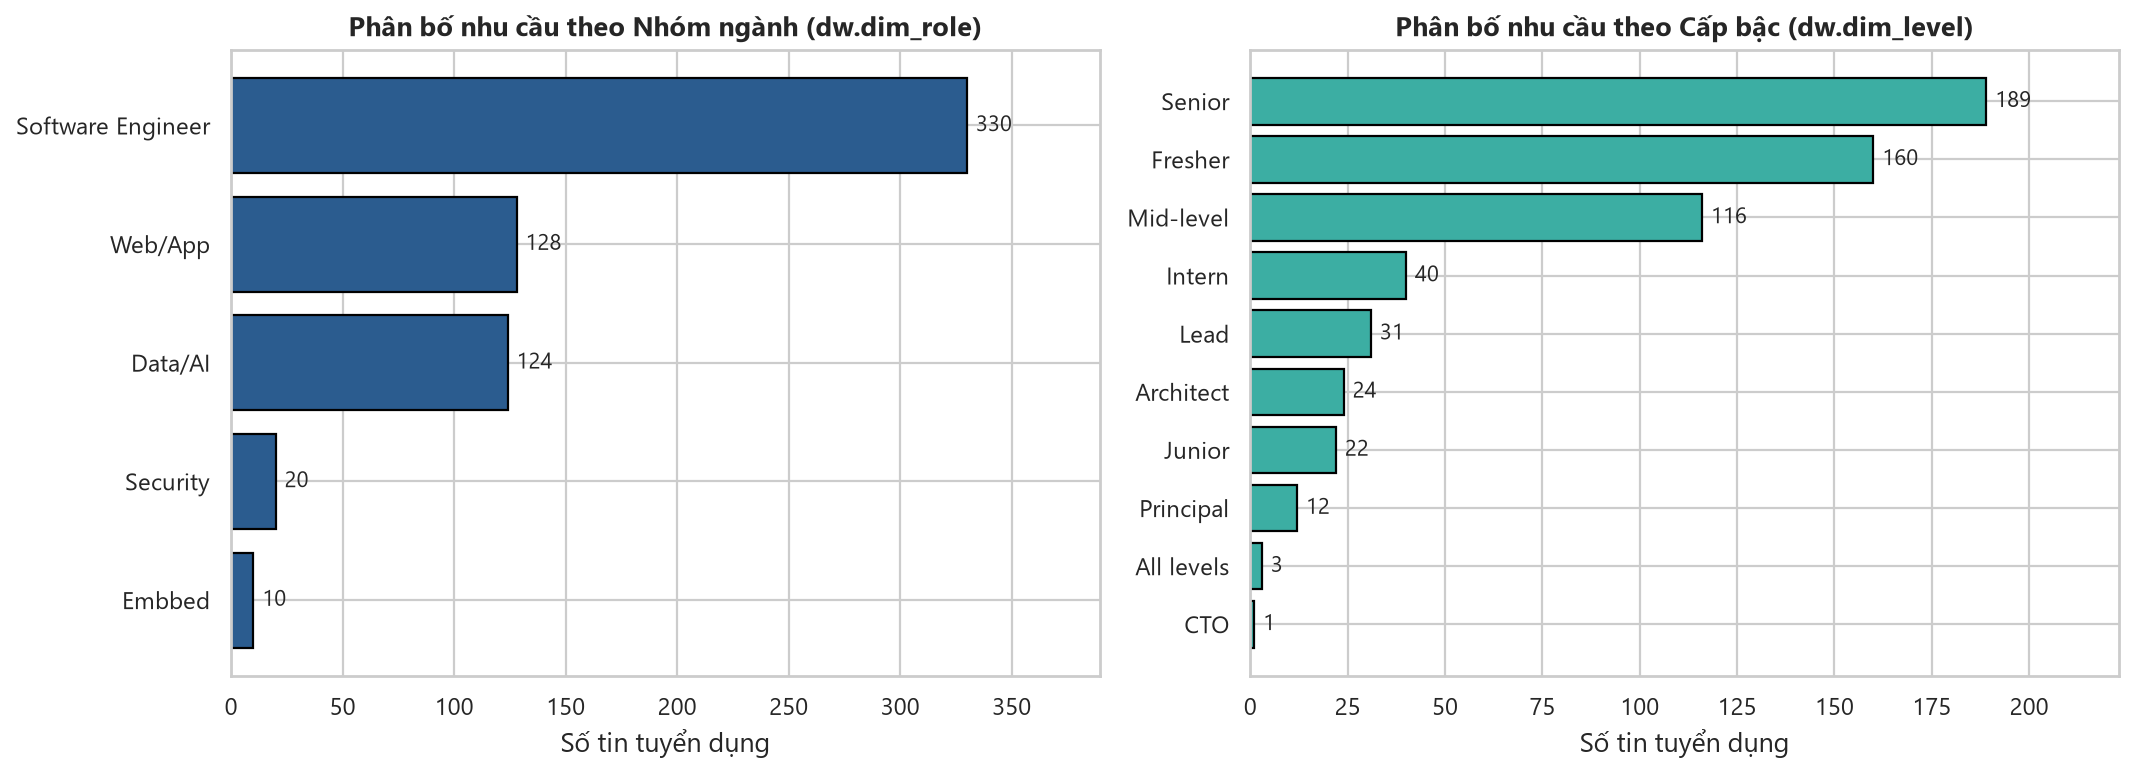

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))

cat_counts = roles.groupby("role_category")["fact_job_key"].nunique().sort_values(ascending=True)
b1 = axes[0].barh(cat_counts.index, cat_counts.values, color="#2b5c8f", edgecolor="black")
axes[0].bar_label(b1, padding=4)
axes[0].set_title("Phân bố nhu cầu theo Nhóm ngành (dw.dim_role)", fontweight="bold")
axes[0].set_xlabel("Số tin tuyển dụng")

lvl_counts = levels.groupby("level_name")["fact_job_key"].nunique().sort_values(ascending=True)
b2 = axes[1].barh(lvl_counts.index, lvl_counts.values, color="#3caea3", edgecolor="black")
axes[1].bar_label(b2, padding=4)
axes[1].set_title("Phân bố nhu cầu theo Cấp bậc (dw.dim_level)", fontweight="bold")
axes[1].set_xlabel("Số tin tuyển dụng")

plt.tight_layout()
plt.show()

## Phần 3: Bài toán 1 — Dự đoán những Kỹ năng cần thiết cho Sinh viên CNTT
- **Mục tiêu**: Dự báo xác suất các kỹ năng (`programming_language`, `framework`, `core_skill`, `foreign_language`) mà sinh viên cần trang bị khi hướng tới một **Vị trí (`role`)**, **Cấp bậc (`level`)** và **Thành phố (`city`)** cụ thể.
- **Phương pháp**: Phân loại đa nhãn (*Multi-Label Classification*) với `OneVsRestClassifier`.

### 3.1. Chuẩn bị ma trận đặc trưng ngữ cảnh ($X$) và ma trận nhãn kỹ năng ($Y$)

In [6]:
all_job_keys = sorted(jobs["fact_job_key"].unique())

def make_pivot(df, col, prefix):
    p = (
        df.assign(val=1)
        .pivot_table(index="fact_job_key", columns=col, values="val", aggfunc="max", fill_value=0)
        .reindex(all_job_keys, fill_value=0)
    )
    p.columns = [f"{prefix}::{c}" for c in p.columns]
    return p

X_context = pd.concat([
    make_pivot(roles, "role_name", "role"),
    make_pivot(roles, "role_category", "cat"),
    make_pivot(levels, "level_name", "level"),
    make_pivot(cities, "city_name", "city"),
], axis=1)

skills_c = skills.copy()
skills_c["label"] = skills_c["skill_type"] + "::" + skills_c["skill_name"]
skill_counts = skills_c.groupby("label")["fact_job_key"].nunique()
target_labels = skill_counts[skill_counts >= 12].sort_values(ascending=False).index.tolist()

Y_skills = (
    skills_c[skills_c["label"].isin(target_labels)]
    .assign(val=1)
    .pivot_table(index="fact_job_key", columns="label", values="val", aggfunc="max", fill_value=0)
    .reindex(index=all_job_keys, columns=target_labels, fill_value=0)
)

valid_mask = Y_skills.sum(axis=1) > 0
X_val = X_context.loc[valid_mask].values
Y_val = Y_skills.loc[valid_mask].values

print(f"- Ma trận đặc trưng ngữ cảnh X_val : {X_val.shape[0]} mẫu x {X_val.shape[1]} đặc trưng (Role, Category, Level, City)")
print(f"- Ma trận đa nhãn kỹ năng Y_val    : {Y_val.shape[0]} mẫu x {Y_val.shape[1]} kỹ năng mục tiêu (tần suất >= 12 tin)")

- Ma trận đặc trưng ngữ cảnh X_val : 571 mẫu x 80 đặc trưng (Role, Category, Level, City)
- Ma trận đa nhãn kỹ năng Y_val    : 571 mẫu x 61 kỹ năng mục tiêu (tần suất >= 12 tin)


### 3.2. Huấn luyện & Đánh giá các mô hình Multi-Label (5-Fold Cross-Validation)

In [7]:
def precision_at_k(y_true, y_prob, k=5):
    hits = []
    for i in range(len(y_true)):
        tset = set(np.where(y_true[i] == 1)[0])
        if not tset:
            continue
        topk = np.argsort(y_prob[i])[::-1][:k]
        hits.append(len(tset.intersection(topk)) / min(k, len(tset)))
    return float(np.mean(hits)) if hits else 0.0

t1_models = {
    "Random Forest (Multi-Label)": OneVsRestClassifier(
        RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, class_weight="balanced_subsample")
    ),
    "Extra Trees (Multi-Label)": OneVsRestClassifier(
        ExtraTreesClassifier(n_estimators=200, max_depth=12, random_state=42, class_weight="balanced_subsample")
    ),
    "Logistic Regression (Multi-Label)": OneVsRestClassifier(
        LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced", random_state=42)
    ),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
t1_rows = []
for mname, clf in t1_models.items():
    yt_l, yp_l, ypr_l = [], [], []
    for tr, te in kf.split(X_val):
        clf.fit(X_val[tr], Y_val[tr])
        yp_l.append(clf.predict(X_val[te]))
        ypr_l.append(clf.predict_proba(X_val[te]))
        yt_l.append(Y_val[te])
    yt, yp, ypr = np.vstack(yt_l), np.vstack(yp_l), np.vstack(ypr_l)
    t1_rows.append({
        "Mô hình Multi-Label": mname,
        "Hamming Accuracy": round(1.0 - hamming_loss(yt, yp), 4),
        "HitRate@5": round(precision_at_k(yt, ypr, 5), 4),
        "Micro F1": round(f1_score(yt, yp, average="micro", zero_division=0), 4),
        "Macro F1": round(f1_score(yt, yp, average="macro", zero_division=0), 4),
        "ROC-AUC (Micro)": round(roc_auc_score(yt, ypr, average="micro"), 4),
    })

t1_cv_df = pd.DataFrame(t1_rows)
best_t1_clf = t1_models["Random Forest (Multi-Label)"]
best_t1_clf.fit(X_val, Y_val)
t1_cv_df

Mô hình Multi-Label,Hamming Accuracy,HitRate@5,Micro F1,Macro F1,ROC-AUC (Micro)
Random Forest (Multi-Label),0.9113,0.5015,0.3718,0.2956,0.8219
Extra Trees (Multi-Label),0.8914,0.4641,0.3505,0.2925,0.8145
Logistic Regression (Multi-Label),0.8367,0.4453,0.3294,0.3051,0.8347


### 3.3. Bảng dự báo Top kỹ năng cần thiết cho Sinh viên (Fresher / Junior) theo từng vị trí

In [8]:
student_roles = [
    ("Back-end Developer", "Web/App"),
    ("Full-stack Developer", "Web/App"),
    ("AI Engineer", "Data/AI"),
    ("Data Engineer", "Data/AI"),
    ("Tester", "Software Engineer"),
    ("Business Analyst", "Software Engineer"),
    ("DevOps Engineer", "Software Engineer"),
    ("Systems Engineer", "Software Engineer"),
]

role_preds = {}
role_table_rows = []
for rname, rcat in student_roles:
    xq = pd.Series(0.0, index=X_context.columns)
    for col_key in (f"role::{rname}", f"cat::{rcat}", "level::Fresher", "level::Junior", "city::Ho Chi Minh"):
        if col_key in xq.index:
            xq[col_key] = 1.0
    pr = best_t1_clf.predict_proba(xq.values.reshape(1, -1))[0]
    r_jkeys = roles[roles["role_name"] == rname]["fact_job_key"].unique()
    emp = Y_skills.loc[Y_skills.index.intersection(r_jkeys)].mean(axis=0).values if len(r_jkeys) else np.zeros_like(pr)
    score = 0.6 * pr + 0.4 * emp
    ranked = np.argsort(score)[::-1]
    role_preds[rname] = {target_labels[idx].split("::", 1)[1]: round(float(score[idx]), 3) for idx in ranked}

    top6_str = ", ".join(f"{target_labels[idx].split('::', 1)[1]} ({score[idx]:.2f})" for idx in ranked[:6])
    role_table_rows.append({
        "Vị trí định hướng": rname,
        "Nhóm ngành": rcat,
        "Cấp bậc mục tiêu": "Fresher / Junior",
        "Top 6 Kỹ năng cần thiết nhất (Điểm dự báo ML)": top6_str,
    })

role_pred_df = pd.DataFrame(role_table_rows)
role_pred_df

Vị trí định hướng,Nhóm ngành,Cấp bậc mục tiêu,Top 6 Kỹ năng cần thiết nhất (Điểm dự báo ML)
Back-end Developer,Web/App,Fresher / Junior,"English (0.43), Go (0.42), Java (0.37), SQL (0.36), Microservices (0.36), Spring (0.29)"
Full-stack Developer,Web/App,Fresher / Junior,"English (0.50), TypeScript (0.46), React (0.46), Fullstack (0.43), Node.js (0.42), SQL (0.36)"
AI Engineer,Data/AI,Fresher / Junior,"Python (0.78), AI (0.66), LLM (0.47), English (0.45), Machine Learning (0.41), React (0.27)"
Data Engineer,Data/AI,Fresher / Junior,"Python (0.73), SQL (0.67), English (0.40), AWS (0.29), Oracle (0.17), Database (0.16)"
Tester,Software Engineer,Fresher / Junior,"English (0.68), QA/QC (0.55), Automation Test (0.44), Agile (0.35), Scrum (0.31), Jira (0.28)"
Business Analyst,Software Engineer,Fresher / Junior,"Business Analysis (0.77), English (0.71), Agile (0.41), SQL (0.36), Figma (0.33), ERP (0.33)"
DevOps Engineer,Software Engineer,Fresher / Junior,"DevOps (0.91), AWS (0.61), English (0.61), CI/CD (0.46), Kubernetes (0.46), Cloud (0.44)"
Systems Engineer,Software Engineer,Fresher / Junior,"English (0.62), System Admin (0.33), AWS (0.33), DevOps (0.32), Linux (0.30), Networking (0.25)"


### 3.4. Heatmap Ma trận Dự báo Kỹ năng cần thiết theo Vị trí Nghề nghiệp

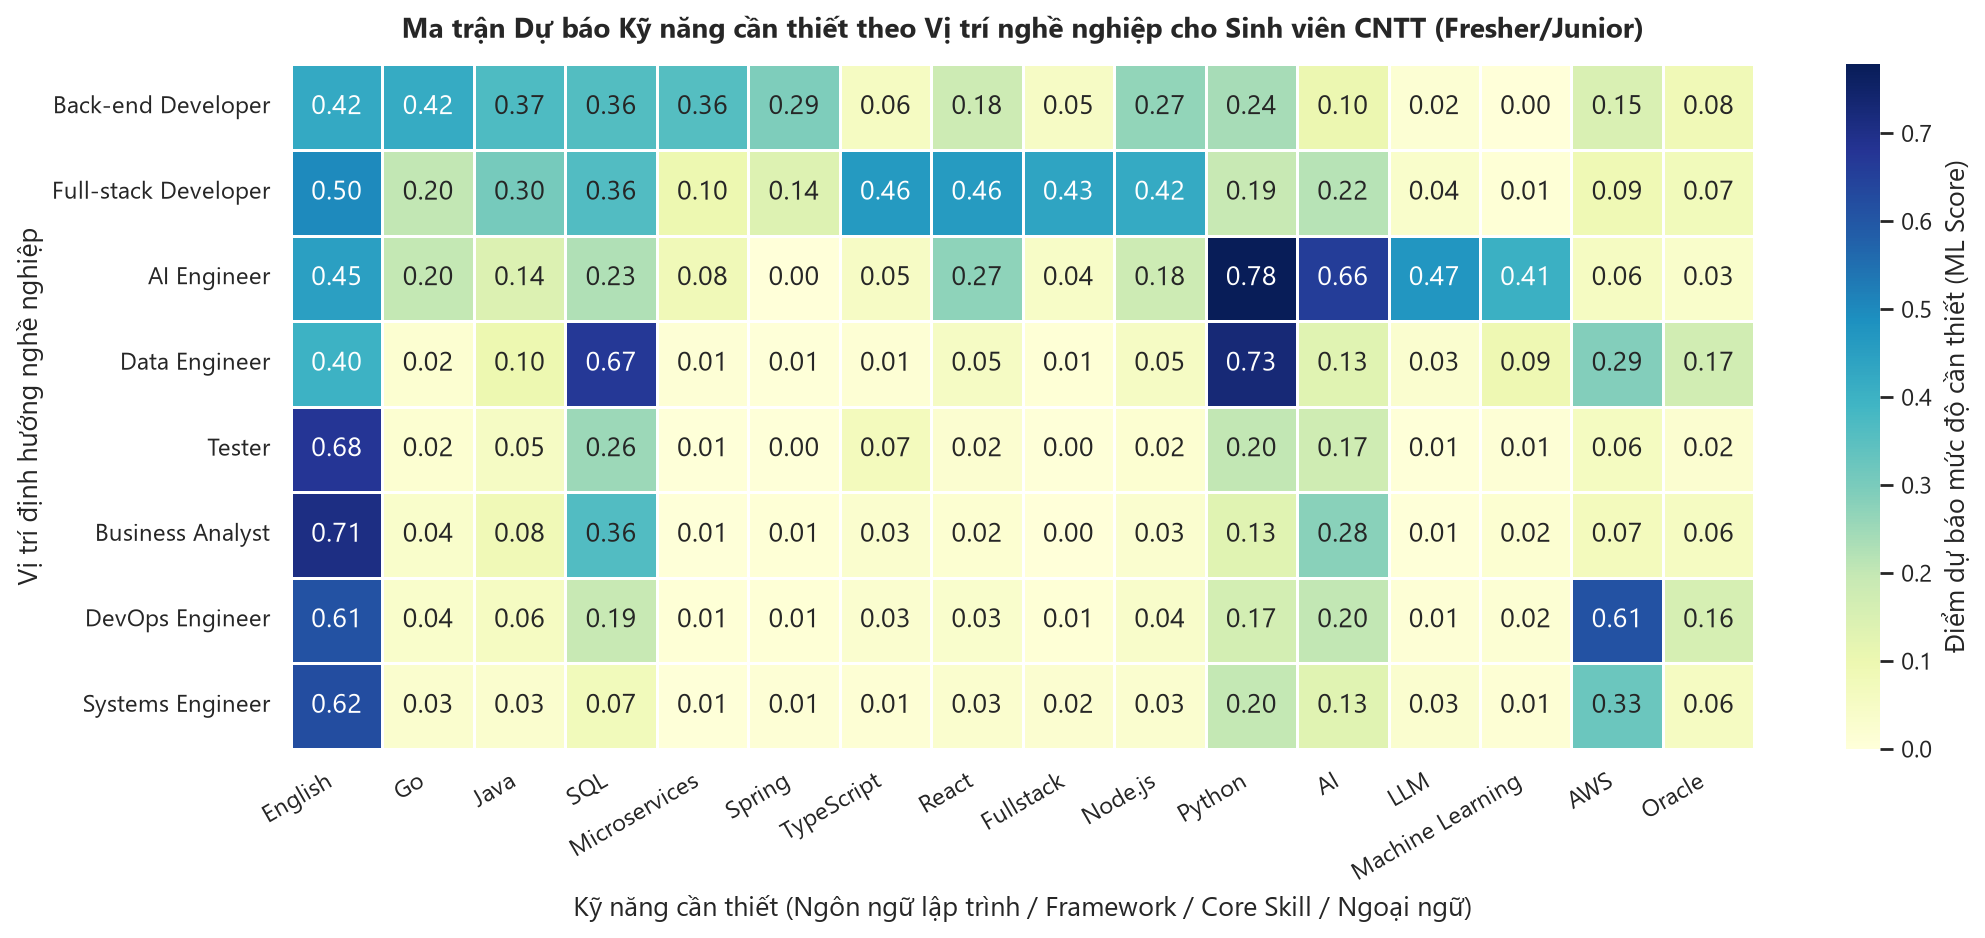

In [9]:
union_skills = []
for rname, _ in student_roles:
    for sname in list(role_preds[rname].keys())[:6]:
        if sname not in union_skills:
            union_skills.append(sname)
union_skills = union_skills[:16]

heat_df = pd.DataFrame(0.0, index=[r for r, _ in student_roles], columns=union_skills)
for rname, _ in student_roles:
    for s in union_skills:
        heat_df.loc[rname, s] = role_preds[rname].get(s, 0.0)

fig, ax = plt.subplots(figsize=(13.5, 6.0))
sns.heatmap(
    heat_df, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5,
    cbar_kws={"label": "Điểm dự báo mức độ cần thiết (ML Score)"}, ax=ax
)
ax.set_title("Ma trận Dự báo Kỹ năng cần thiết theo Vị trí nghề nghiệp cho Sinh viên CNTT (Fresher/Junior)", fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Phần 4: Bài toán 2 — Định hướng Nhóm Nghề nghiệp từ Hồ sơ Kỹ năng của Sinh viên
- **Mục tiêu**: Từ tập kỹ năng hiện có của sinh viên ($X_{\text{skills}}$), dự đoán nhóm nghề nghiệp phù hợp nhất ($y_{\text{career}} \in \{\text{Data/AI}, \text{Web/App}, \text{Software Engineer}, \text{Security}, \text{Embbed}\}$) và xác định các kỹ năng có sức phân loại nghề nghiệp cao nhất.

### 4.1. Xây dựng ma trận đặc trưng kỹ năng ($X_{\text{skills}}$) và phân bố nhãn nhóm ngành ($y_{\text{career}}$)

In [10]:
priority = {"Data/AI": 1, "Security": 2, "Embbed": 3, "Web/App": 4, "Software Engineer": 5}
roles_p = roles.copy()
roles_p["prio"] = roles_p["role_category"].map(lambda c: priority.get(c, 9))
primary_roles = (
    roles_p.sort_values(["fact_job_key", "prio"])
    .drop_duplicates(subset=["fact_job_key"], keep="first")
    .set_index("fact_job_key")
)

sel_feats = skill_counts[skill_counts >= 3].sort_values(ascending=False).index.tolist()
X_skills_df = (
    skills_c[skills_c["label"].isin(sel_feats)]
    .assign(val=1)
    .pivot_table(index="fact_job_key", columns="label", values="val", aggfunc="max", fill_value=0)
)

common_keys = sorted(set(X_skills_df.index).intersection(set(primary_roles.index)))
X2_df = X_skills_df.loc[common_keys]
y2_s = primary_roles.loc[common_keys, "role_category"]
X2, y2 = X2_df.values, y2_s.values

dist_df = y2_s.value_counts().reset_index()
dist_df.columns = ["Nhóm ngành (Role Category)", "Số tin tuyển dụng"]
dist_df["Tỷ lệ (%)"] = (dist_df["Số tin tuyển dụng"] * 100.0 / len(y2_s)).round(1)
dist_df

Nhóm ngành (Role Category),Số tin tuyển dụng,Tỷ lệ (%)
Software Engineer,304,52.5
Data/AI,124,21.4
Web/App,121,20.9
Security,20,3.5
Embbed,10,1.7


### 4.2. So sánh hiệu năng 3 mô hình Định hướng Nghề nghiệp (5-Fold Stratified Cross-Validation)

In [11]:
t2_classifiers = {
    "Gradient Boosting Classifier": GradientBoostingClassifier(
        n_estimators=150, max_depth=4, learning_rate=0.08, random_state=42
    ),
    "Logistic Regression (Multinomial)": LogisticRegression(
        max_iter=1000, C=1.5, class_weight="balanced", random_state=42
    ),
    "Random Forest Classifier": RandomForestClassifier(
        n_estimators=300, max_depth=15, class_weight="balanced", random_state=42
    ),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
t2_rows = []
for mname, clf in t2_classifiers.items():
    yt_l, yp_l, ypr_l = [], [], []
    for tr, te in skf.split(X2, y2):
        clf.fit(X2[tr], y2[tr])
        yp_l.append(clf.predict(X2[te]))
        ypr_l.append(clf.predict_proba(X2[te]))
        yt_l.append(y2[te])
    yt, yp, ypr = np.concatenate(yt_l), np.concatenate(yp_l), np.vstack(ypr_l)
    t2_rows.append({
        "Mô hình Phân loại": mname,
        "Accuracy": round(accuracy_score(yt, yp), 4),
        "Weighted F1": round(f1_score(yt, yp, average="weighted", zero_division=0), 4),
        "Weighted Precision": round(precision_score(yt, yp, average="weighted", zero_division=0), 4),
        "Weighted Recall": round(recall_score(yt, yp, average="weighted", zero_division=0), 4),
        "ROC-AUC (OvR)": round(roc_auc_score(yt, ypr, multi_class="ovr", average="weighted"), 4),
    })

t2_cv_df = pd.DataFrame(t2_rows)
t2_cv_df

Mô hình Phân loại,Accuracy,Weighted F1,Weighted Precision,Weighted Recall,ROC-AUC (OvR)
Gradient Boosting Classifier,0.7513,0.7500,0.7520,0.7513,0.8861
Logistic Regression (Multinomial),0.7461,0.7502,0.7587,0.7461,0.9009
Random Forest Classifier,0.7271,0.7299,0.7384,0.7271,0.8767


### 4.3. Biểu đồ So sánh Mô hình & Top 15 Kỹ năng quyết định Định hướng Nghề nghiệp (`Feature Importance`)

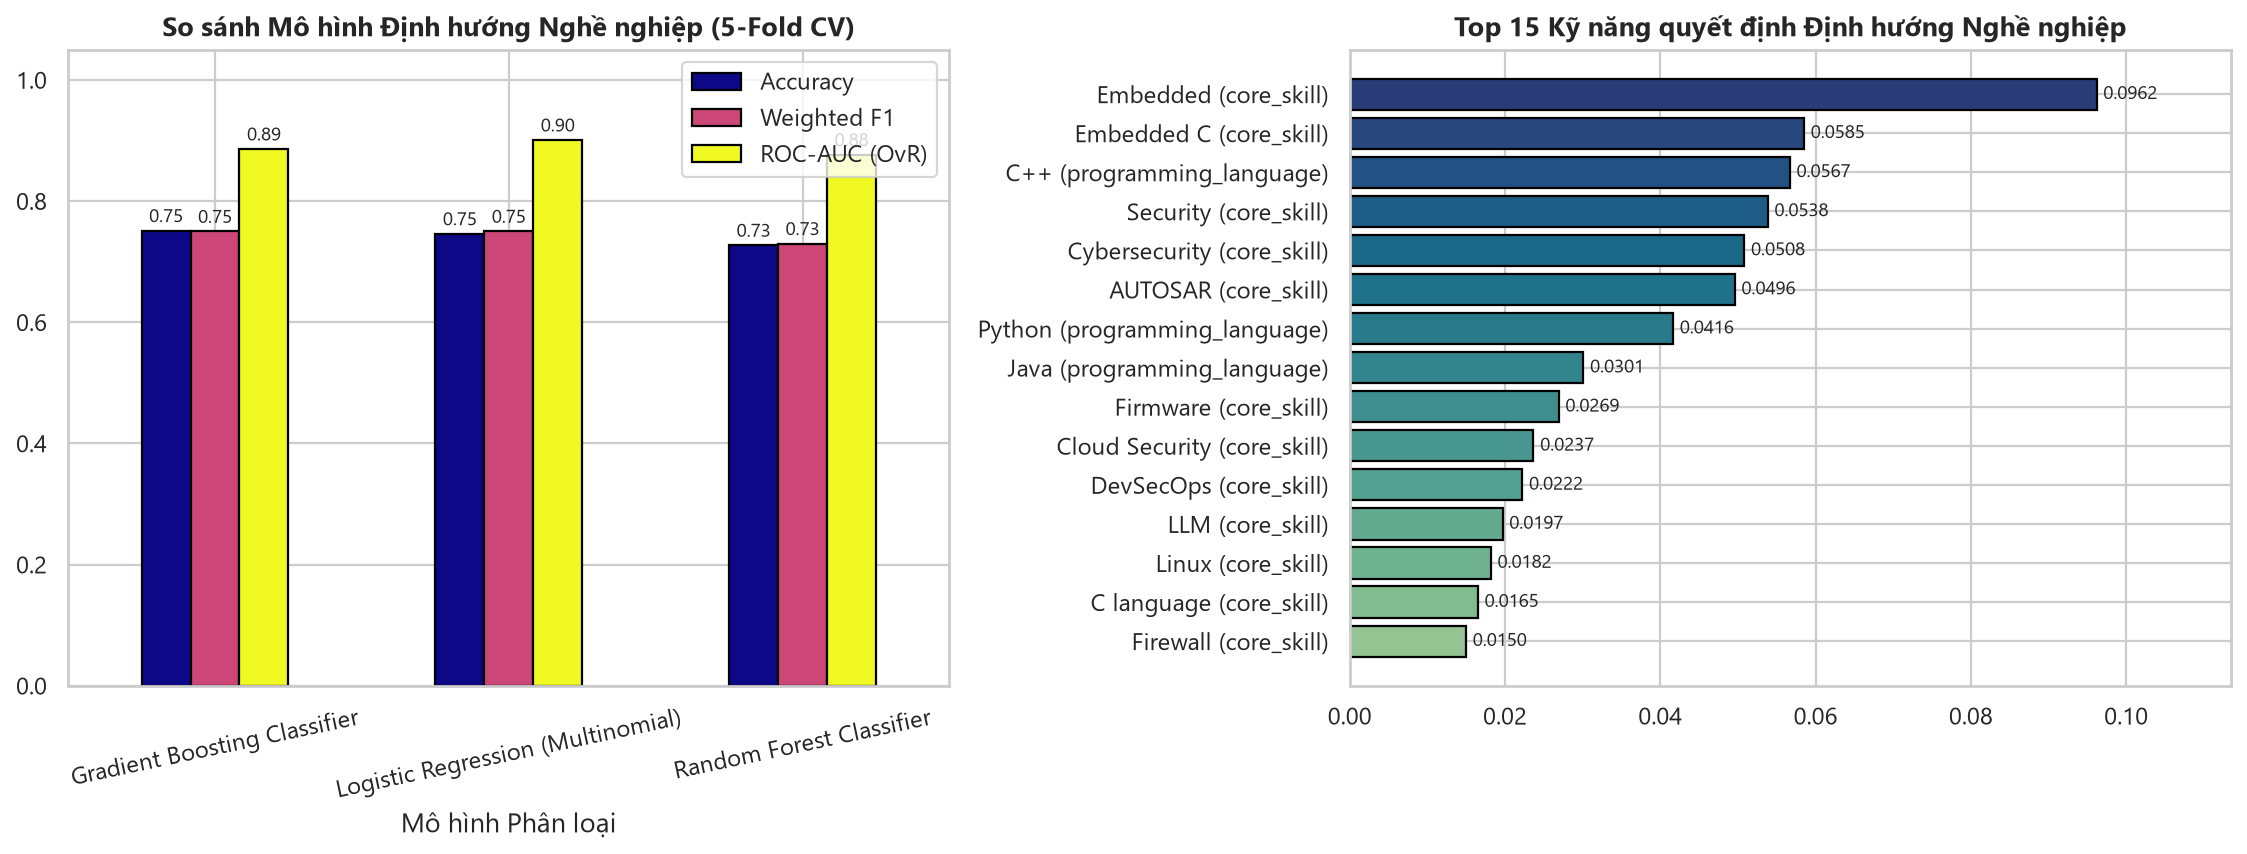

In [12]:
rf_career = t2_classifiers["Random Forest Classifier"]
rf_career.fit(X2, y2)
importances = pd.Series(rf_career.feature_importances_, index=X2_df.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14.2, 5.5))
t2_cv_df.set_index("Mô hình Phân loại")[["Accuracy", "Weighted F1", "ROC-AUC (OvR)"]].plot(
    kind="bar", ax=axes[0], rot=12, colormap="plasma", edgecolor="black"
)
axes[0].set_title("So sánh Mô hình Định hướng Nghề nghiệp (5-Fold CV)", fontweight="bold")
axes[0].set_ylim(0, 1.05)

top15_imp = importances.head(15)[::-1]
clean_lbls = [f"{k.split('::', 1)[1]} ({k.split('::', 1)[0]})" for k in top15_imp.index]
bars = axes[1].barh(clean_lbls, top15_imp.values, color=sns.color_palette("crest", len(top15_imp)), edgecolor="black")
axes[1].bar_label(bars, fmt="%.4f", padding=3)
axes[1].set_title("Top 15 Kỹ năng quyết định Định hướng Nghề nghiệp", fontweight="bold")

plt.tight_layout()
plt.show()

## Phần 5: Hệ thống Gợi ý Lộ trình Học tập (Skill Gap) & Định hướng Nghề nghiệp cho Sinh viên
Kết hợp cả 2 mô hình đã huấn luyện:
- **Model 2 (`rf_career`)**: Đánh giá bộ kỹ năng hiện có của sinh viên phù hợp bao nhiêu % với từng nhóm ngành.
- **Model 1 (`best_t1_clf`)**: Chỉ ra các kỹ năng quan trọng nhất mà sinh viên **còn thiếu (Skill Gap)** cần học bổ sung để ứng tuyển vị trí mục tiêu.

### 5.1. Hàm gợi ý lộ trình cho sinh viên

In [13]:
def recommend_row(student_name: str, target_role: str, target_level: str, target_city: str, known: list[str]) -> dict:
    known_set = {s.casefold() for s in known}
    x_s = np.zeros((1, len(X2_df.columns)))
    for idx, col in enumerate(X2_df.columns):
        if col.split("::", 1)[1].casefold() in known_set:
            x_s[0, idx] = 1.0
    c_probs = rf_career.predict_proba(x_s)[0]
    c_rank = sorted(zip(rf_career.classes_, c_probs), key=lambda x: x[1], reverse=True)

    xq = pd.Series(0.0, index=X_context.columns)
    for ck in (f"role::{target_role}", f"level::{target_level}", f"city::{target_city}"):
        if ck in xq.index:
            xq[ck] = 1.0
    sp = best_t1_clf.predict_proba(xq.values.reshape(1, -1))[0]
    r_jkeys = roles[roles["role_name"] == target_role]["fact_job_key"].unique()
    emp = Y_skills.loc[Y_skills.index.intersection(r_jkeys)].mean(axis=0).values if len(r_jkeys) else np.zeros_like(sp)
    blended = 0.6 * sp + 0.4 * emp

    missing = []
    for idx in np.argsort(blended)[::-1]:
        st, sn = target_labels[idx].split("::", 1)
        if sn.casefold() not in known_set:
            missing.append(f"{sn} ({blended[idx]:.2f})")
        if len(missing) >= 6:
            break

    top_careers = ", ".join(f"{c} ({p*100:.1f}%)" for c, p in c_rank[:2])
    return {
        "Hồ sơ Sinh viên": student_name,
        "Kỹ năng hiện có": ", ".join(known),
        "Vị trí & Cấp bậc mục tiêu": f"{target_role} ({target_level} - {target_city})",
        "Định hướng Nhóm ngành (Model 2)": top_careers,
        "Top 6 Kỹ năng cần học thêm / Skill Gap (Model 1)": ", ".join(missing),
    }

### 5.2. Kết quả tư vấn mẫu cho 5 hồ sơ sinh viên CNTT

In [14]:
rec_df = pd.DataFrame([
    recommend_row("Sinh viên A (Data)", "Data Engineer", "Fresher", "Ho Chi Minh", ["Python", "SQL"]),
    recommend_row("Sinh viên B (Backend)", "Back-end Developer", "Fresher", "Ho Chi Minh", ["Java", "SQL"]),
    recommend_row("Sinh viên C (AI)", "AI Engineer", "Fresher", "Ha Noi", ["Python", "English"]),
    recommend_row("Sinh viên D (Fullstack)", "Full-stack Developer", "Fresher", "Ho Chi Minh", ["JavaScript", "React"]),
    recommend_row("Sinh viên E (QA/Tester)", "Tester", "Fresher", "Ho Chi Minh", ["SQL", "English"]),
])
rec_df

Hồ sơ Sinh viên,Kỹ năng hiện có,Vị trí & Cấp bậc mục tiêu,Định hướng Nhóm ngành (Model 2),Top 6 Kỹ năng cần học thêm / Skill Gap (Model 1)
Sinh viên A (Data),"Python, SQL",Data Engineer (Fresher - Ho Chi Minh),"Data/AI (64.0%), Software Engineer (17.4%)","English (0.50), AWS (0.30), C# (0.20), PostgreSQL (0.19), .NET (0.18), JavaScript (0.18)"
Sinh viên B (Backend),"Java, SQL",Back-end Developer (Fresher - Ho Chi Minh),"Web/App (53.4%), Software Engineer (22.8%)","English (0.45), Microservices (0.29), Python (0.29), Go (0.29), API (0.27), Docker (0.26)"
Sinh viên C (AI),"Python, English",AI Engineer (Fresher - Ha Noi),"Data/AI (46.5%), Software Engineer (27.0%)","AI (0.55), LLM (0.45), Machine Learning (0.32), API (0.32), SQL (0.26), React (0.26)"
Sinh viên D (Fullstack),"JavaScript, React",Full-stack Developer (Fresher - Ho Chi Minh),"Web/App (55.6%), Software Engineer (22.0%)","English (0.54), SQL (0.38), Java (0.30), Fullstack (0.28), TypeScript (0.28), Node.js (0.27)"
Sinh viên E (QA/Tester),"SQL, English",Tester (Fresher - Ho Chi Minh),"Software Engineer (34.6%), Data/AI (28.8%)","QA/QC (0.53), Automation Test (0.41), Python (0.26), API (0.26), Agile (0.24), Jira (0.23)"
